# How Cristiano Ronaldo's Scoring Rate Evolved Throughout His Career

Cristiano Ronaldo's goalscoring numbers are the focal point of his career, but they do not tell the whole story. Scoring rates help us examine the frequency at which he scored in while accounting for gaps in playing time. This brief analysis looks at Ronaldo's scoring rate season-by-season through goals per game and goals per 90 minutes.

The data was gathered from the match logs. All goals and matches from his career are included in this analysis. Appearances are counted depending on whether he played in the game, while the per 90 statistics sum up the goals and minutes he played in the season, divide the former by the latter, and multiply by 90. The formula is as follows:

(Total Goals / Total Minutes) x 90

In [6]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("../matches")
files = sorted(data_dir.glob("*.json"))

matches = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        season_matches = json.load(f)
        matches.extend(season_matches)

df = pd.DataFrame(matches)

print("Files loaded:", len(files))
print("DataFrame shape:", df.shape)
display(df.head())

Files loaded: 25
DataFrame shape: (1340, 22)


,id,date,season,team,competition,stage,leg,opponent,venue,result,...,minutesPlayed,goals,assists,yellowCard,redCard,hasMatchComp,matchCompUrl,hasFullMatch,fullMatchUrl,stats
0,2002-08-14,2002-08-14,2002/03,Sporting CP,UEFA Champions League Qualifying,Play-off,1st Leg,Inter Milan,Home,D,...,32,0,0,None,None,True,https://vimeo.com/312097381,True,https://footballia.net/matches/sporting-cp-fc-...,NaN
1,2002-09-19,2002-09-19,2002/03,Sporting CP,UEFA Cup,Round of 96,1st Leg,Partizan Belgrade,Home,L,...,45,0,0,None,None,True,https://www.youtube.com/watch?v=BD-JrESn88Q,True,https://footballia.net/matches/sporting-cp-fk-...,NaN
2,2002-09-29,2002-09-29,2002/03,Sporting CP,Primeira Liga,League,NaN,Sporting Braga,Away,L,...,21,0,0,None,None,False,,False,,NaN
3,2002-10-03,2002-10-03,2002/03,Sporting CP,UEFA Cup,Round of 96,2nd Leg,Partizan Belgrade,Away,D,...,74,0,0,None,None,True,https://vimeo.com/224993953,True,https://www.youtube.com/watch?v=CpHapaPu0aw,NaN
4,2002-10-07,2002-10-07,2002/03,Sporting CP,Primeira Liga,League,NaN,Moreirense,Home,W,...,90,2,0,None,None,True,https://youtube.com/watch?v=nVsicMbOniw,False,,NaN


In [7]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

for column in ["goals", "minutesPlayed"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=["date", "season", "goals", "minutesPlayed"])

df = df.sort_values("date").reset_index(drop=True)

df[["date", "season", "goals", "minutesPlayed"]].head()

,date,season,goals,minutesPlayed
0,2002-08-14,2002/03,0,32
1,2002-09-19,2002/03,0,45
2,2002-09-29,2002/03,0,21
3,2002-10-03,2002/03,0,74
4,2002-10-07,2002/03,2,90


In [8]:
season_stats = (
    df.groupby("season", sort=True)
    .agg(
        appearances=("date", "size"),
        goals=("goals", "sum"),
        minutes=("minutesPlayed", "sum")
    )
    .reset_index()
)

season_stats["goals_per_appearance"] = (
    season_stats["goals"] / season_stats["appearances"]
)

season_stats["goals_per_90"] = (
    season_stats["goals"] / season_stats["minutes"] * 90
)

season_stats["goals_per_90"] = (
    season_stats["goals_per_90"].where(season_stats["minutes"] > 0)
)

season_stats.round(2)

,season,appearances,goals,minutes,goals_per_appearance,goals_per_90
0,2002/03,31,5,1392,0.16,0.32
1,2003/04,53,8,3054,0.15,0.24
2,2004/05,60,16,4498,0.27,0.32
3,2005/06,62,15,4543,0.24,0.30
4,2006/07,61,28,5006,0.46,0.50
5,2007/08,61,46,5265,0.75,0.79
6,2008/09,60,27,4895,0.45,0.50
7,2009/10,46,34,3740,0.74,0.82
8,2010/11,59,56,4983,0.95,1.01
9,2011/12,69,69,6116,1.00,1.02


The following graph shows two lines depicting Cristiano Ronaldo's scoring rate per appearance and per 90 minutes. Overall, the two lines are very close, showing minimal difference. His scoring rate first was lower until the 2006/07 season, when it shot up from about 0.3 to 0.5, then shot up again the following season to 0.8 goals per game. In 2008/09, it dropped down, but went right up the following season and remained at that level or higher until the end of the 2017/18 season, which encapsulated his Real Madrid career. Since then, two instances occured where his scoring rate shot up (2019/20 and 2023/24) before slowly declining one season at a time.

The per 90 line is slightly lower due to its accuracy. Since football matches are 90 minutes long, the per 90 calculation is more accurate and lower. Given the previous equation for per 90, the per appearance calculation differs because it multiplies the quotient by 90. The only significant gap in lines comes at the start of his career, which can be attributed to the fact that he was a rotation player when he was younger, coming on or being substituted off, not playing the full 90 minutes.

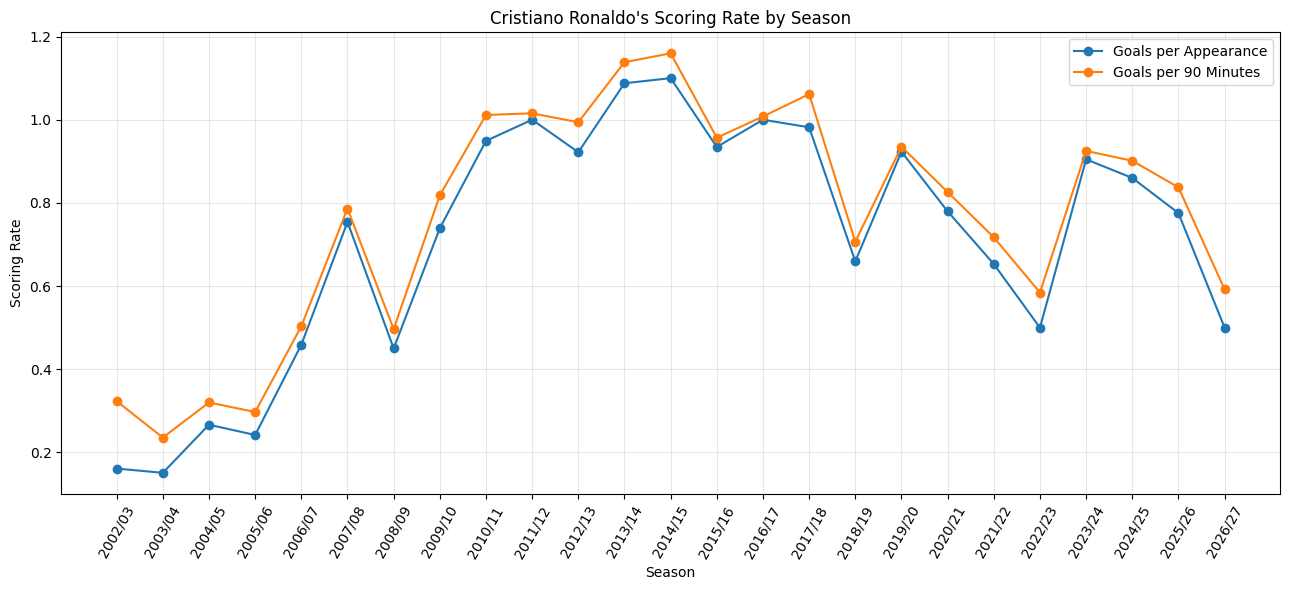

In [13]:
plt.figure(figsize=(13, 6))

plt.plot(
    season_stats["season"],
    season_stats["goals_per_appearance"],
    marker="o",
    color="tab:blue",
    label="Goals per Appearance"
)

plt.plot(
    season_stats["season"],
    season_stats["goals_per_90"],
    marker="o",
    color="tab:orange",
    label="Goals per 90 Minutes"
)

plt.title("Cristiano Ronaldo's Scoring Rate by Season")
plt.xlabel("Season")
plt.ylabel("Scoring Rate")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

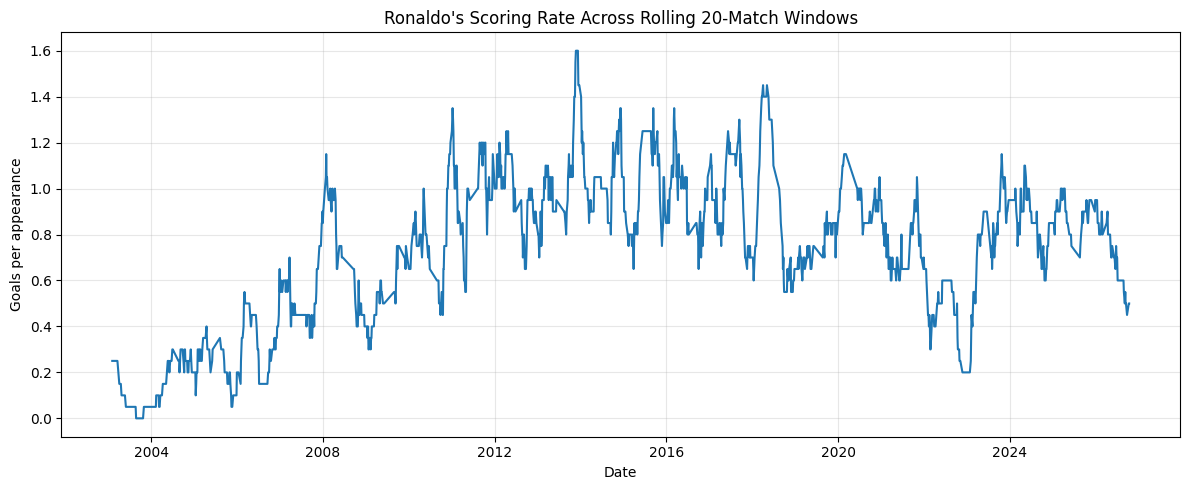

In [12]:
df["rolling_20_goals_per_appearance"] = (
    df["goals"].rolling(window=20, min_periods=20).mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["rolling_20_goals_per_appearance"]
)

plt.title("Ronaldo's Scoring Rate Across Rolling 20-Match Windows")
plt.xlabel("Date")
plt.ylabel("Goals per appearance")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()